# 02 · Selected-series EDA before the first origin

Analyze only the selected 240 series and d_1–d_1801. Parquet loading applies the cutoff filter before analytical calculations. No development or final-holdout future targets influence distributions, representative selection, rolling statistics, correlations or figures. All plots and findings are reproducible through `python -m src.data.eda`.

This notebook describes **observed sales**, with unknown stock availability. Zeros are not confirmed stockouts; absent prices are not proof of unavailability. Associations below are not causal effects.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

cwd = Path.cwd().resolve()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / "experiment.yaml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import load_config, data_path
cfg = load_config()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.max_rows", 25)
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}")


Python 3.14.6, pandas 3.0.6


In [2]:
from src.data.eda import run_eda
safe, stats, summaries, facts = run_eda(cfg)
assert safe.day_num.max() <= cfg["selection"]["cutoff_day"]
print(f"Analytical rows: {len(safe):,}; series: {safe.series_id.nunique()}; "
      f"d_{safe.day_num.min()}–d_{safe.day_num.max()}, "
      f"{safe.date.min().date()}–{safe.date.max().date()}")

Analytical rows: 432,240; series: 240; d_1–d_1801, 2011-01-29–2016-01-03


## Sales distribution and scale

Per-series variance and standard deviation use ddof=1; CV is standard deviation / mean (undefined for zero mean). Log(1 + sales) preserves zeros in the distribution plot. Selection bands use a trailing mean, while these summaries describe all safe history.

,series_id,volume_group,mean,median,variance,std,maximum,cv
0,FOODS_1_004__TX_2,high,7.1749,5.0,68.5777,8.2812,61.0,1.1542
1,FOODS_1_019__WI_1,high,3.5169,3.0,12.0054,3.4649,21.0,0.9852
2,FOODS_1_026__CA_2,medium,0.7646,0.0,1.4445,1.2019,9.0,1.5720
3,FOODS_1_038__WI_2,low,0.3692,0.0,0.6353,0.7970,16.0,2.1586
4,FOODS_1_056__WI_2,low,0.1455,0.0,0.2422,0.4921,5.0,3.3827


,volume_group,series,median_mean,median_cv,median_zero_fraction,median_max_zero_run,median_acf_7,median_price_corr
0,low,80,0.1449,3.2745,0.8906,403.5,0.0801,-0.0385
1,medium,80,0.4209,2.2036,0.7438,430.0,0.1819,-0.0263
2,high,80,1.5738,1.4603,0.4303,236.5,0.3164,-0.0560


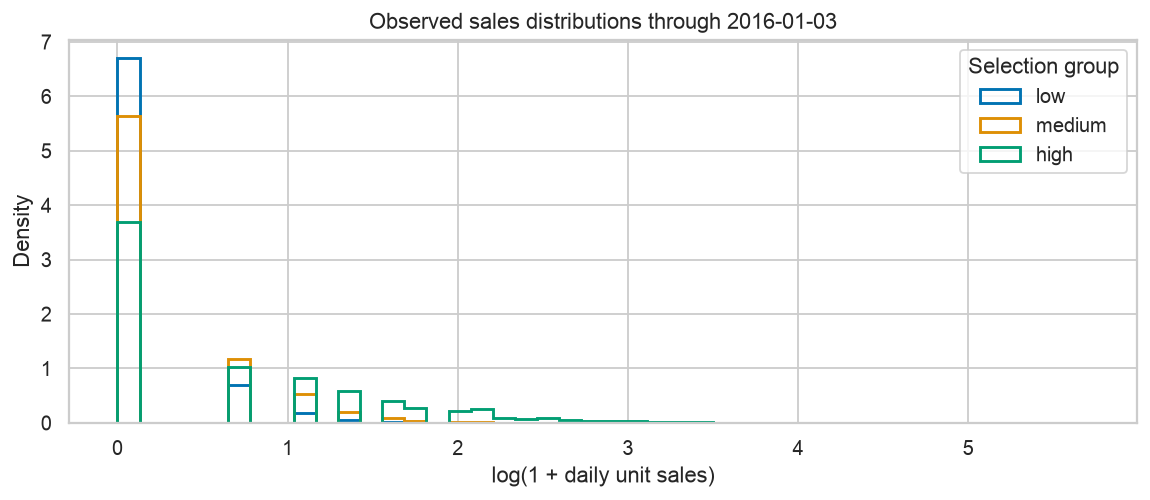

In [3]:
display(stats[["series_id", "volume_group", "mean", "median", "variance", "std", "maximum", "cv"]].head(5).round(4))
display(pd.DataFrame(facts["group_summary"]).round(4))
display(Image(filename=str(data_path(cfg, "reports") / "figures/01_sales_distribution.png")))

## Representative histories and trailing rolling means

For each volume band, choose the series nearest the band's median safe-history mean (deterministically). The full histories and last 365 days with trailing 7/28-day means show variability without using future values. Representatives are illustrations, not coverage of every category/state.

Representative series: {'low': 'FOODS_1_056__WI_2', 'medium': 'FOODS_2_351__WI_1', 'high': 'FOODS_3_194__WI_2'}


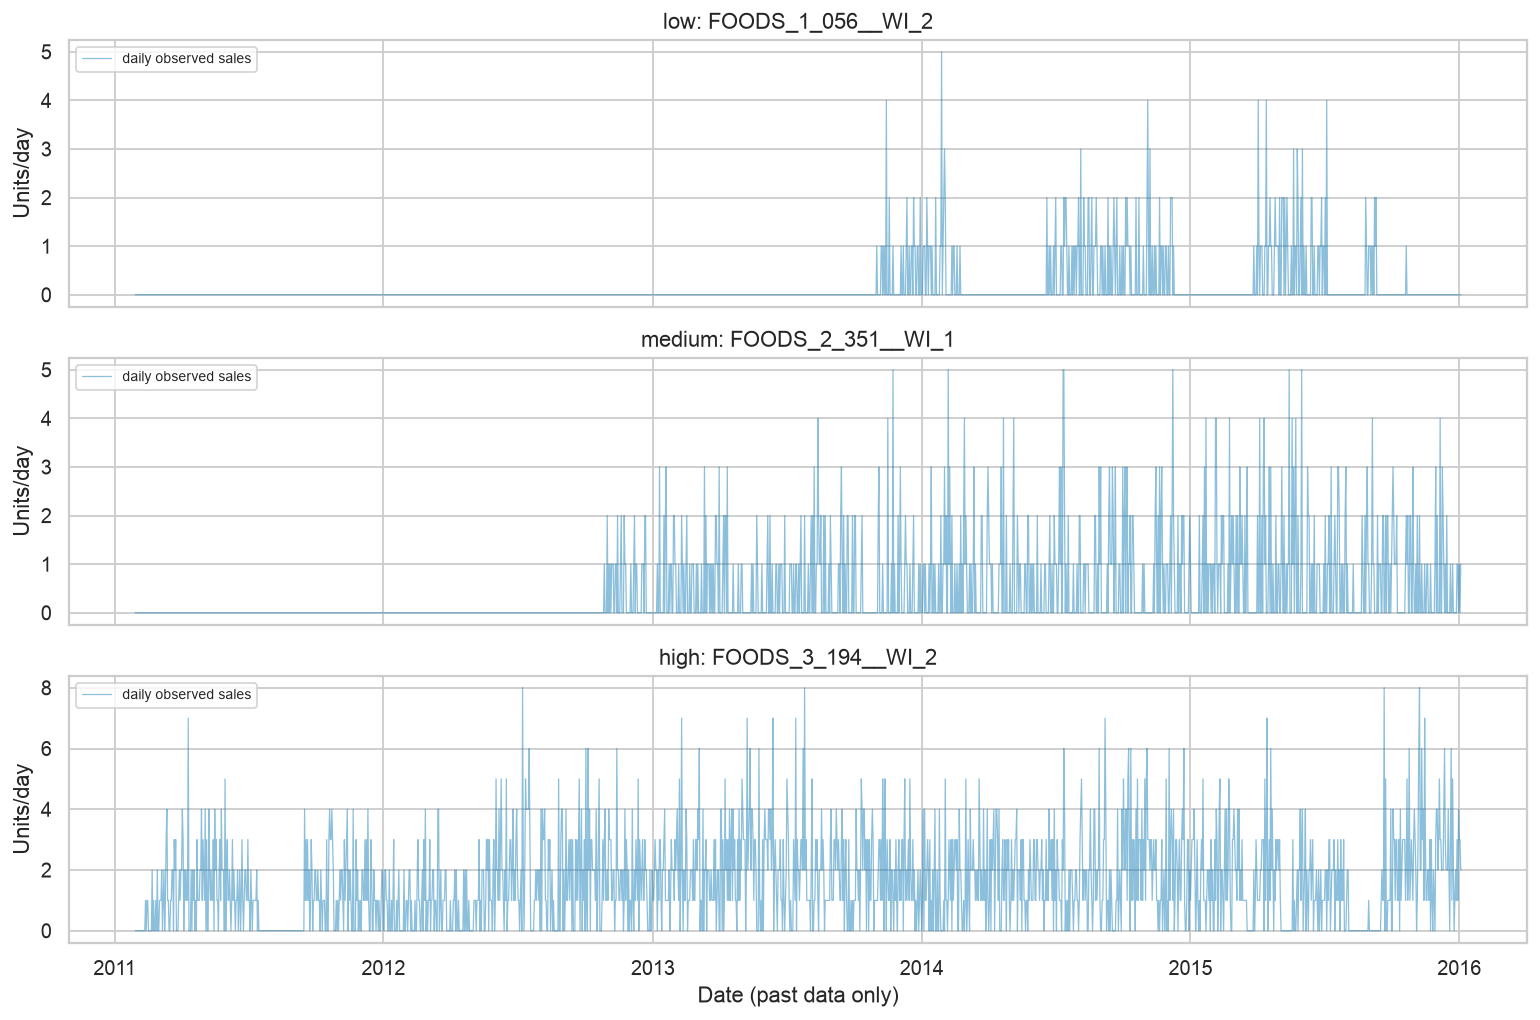

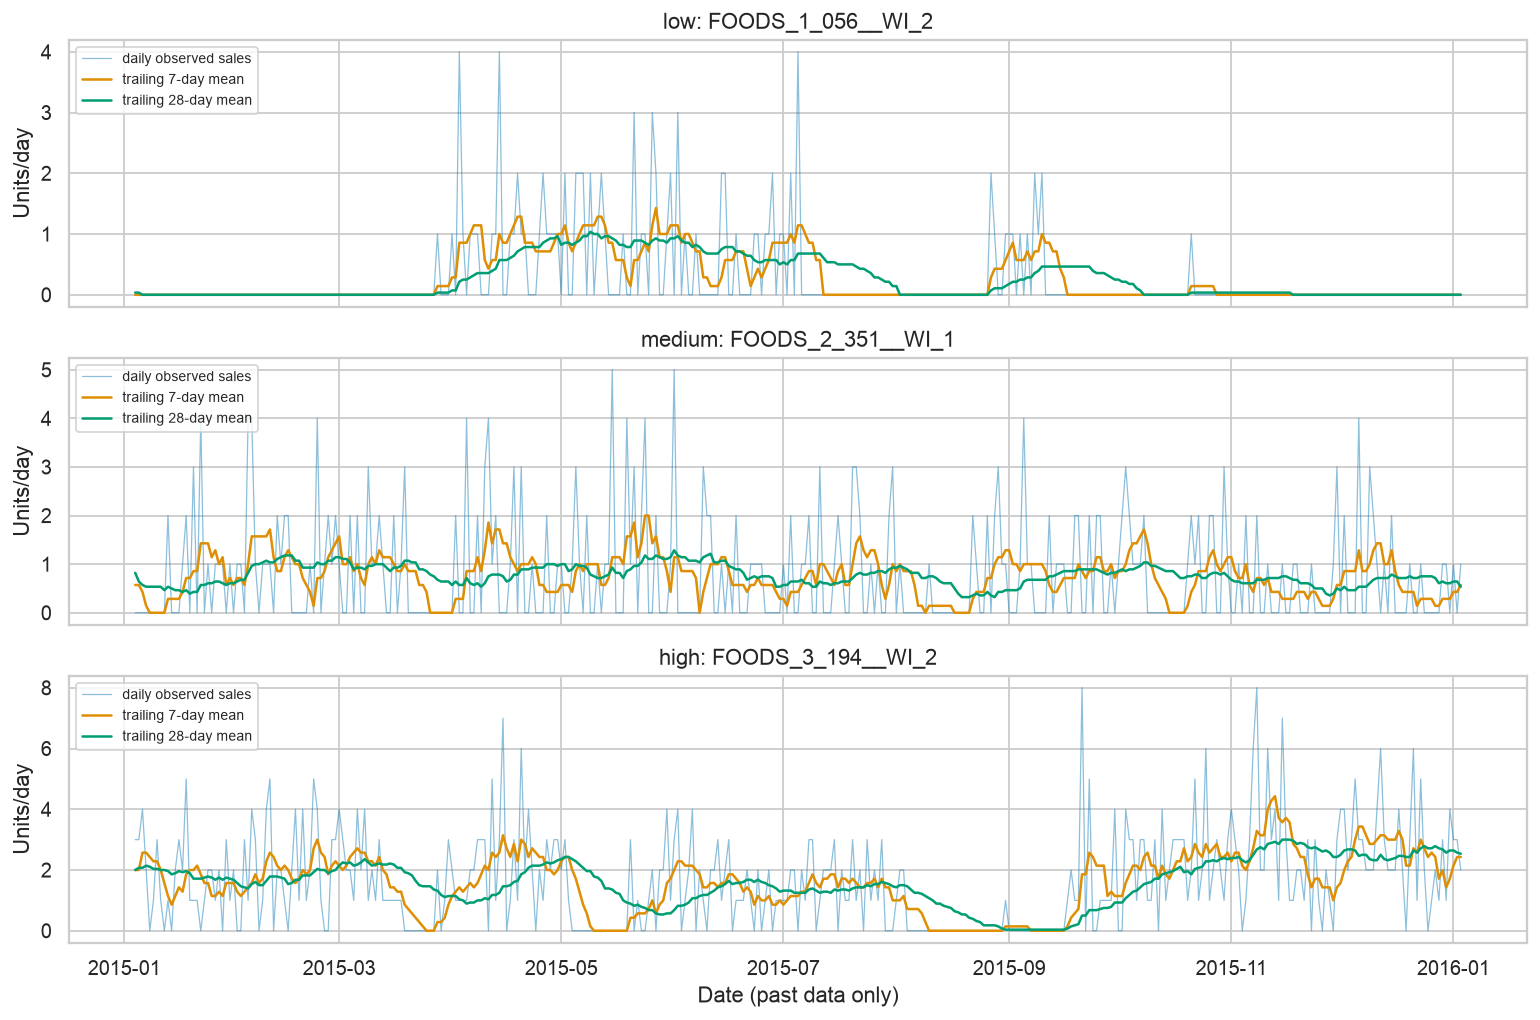

In [4]:
print("Representative series:", facts["representative_series"])
for name in ["02_representative_histories.png", "03_rolling_averages.png"]:
    display(Image(filename=str(data_path(cfg, "reports") / "figures" / name)))

## Weekly/monthly patterns and autocorrelation

Normalize each series by its own safe-history mean, calculate its weekday/month profile, then average equally across series. These are unadjusted descriptive patterns. Autocorrelations are per-series finite-pair Pearson correlations; constants give NA.

Median autocorrelations: {'1': 0.1727614923806651, '7': 0.16390045053831753, '14': 0.14589667007910778, '28': 0.13482013453338512}


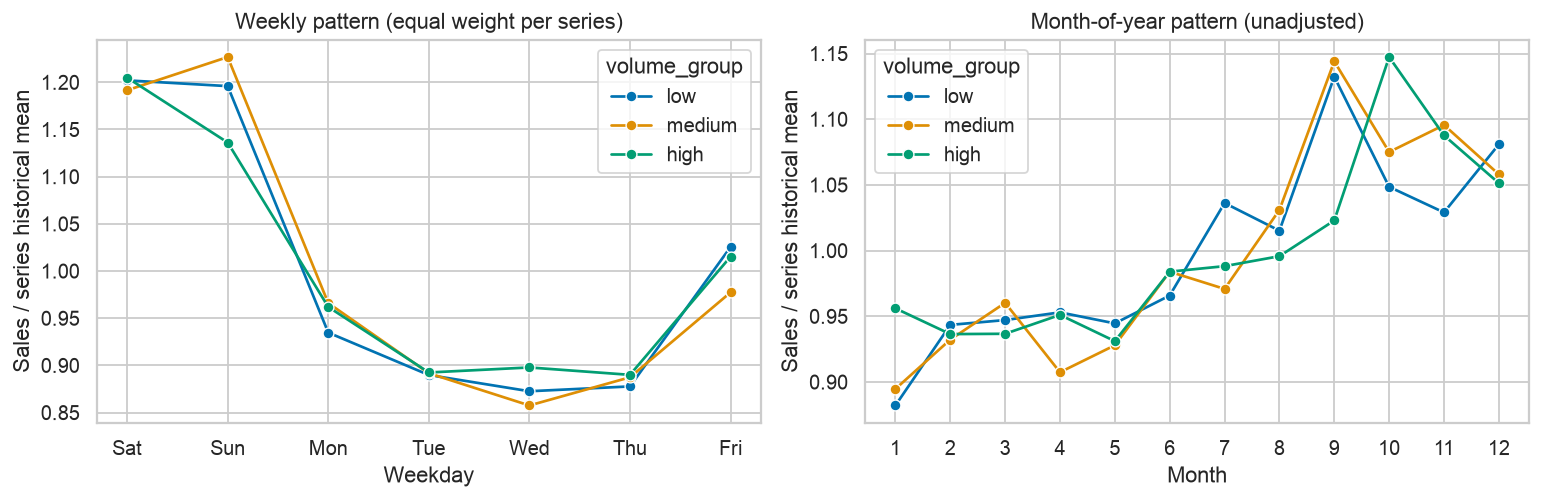

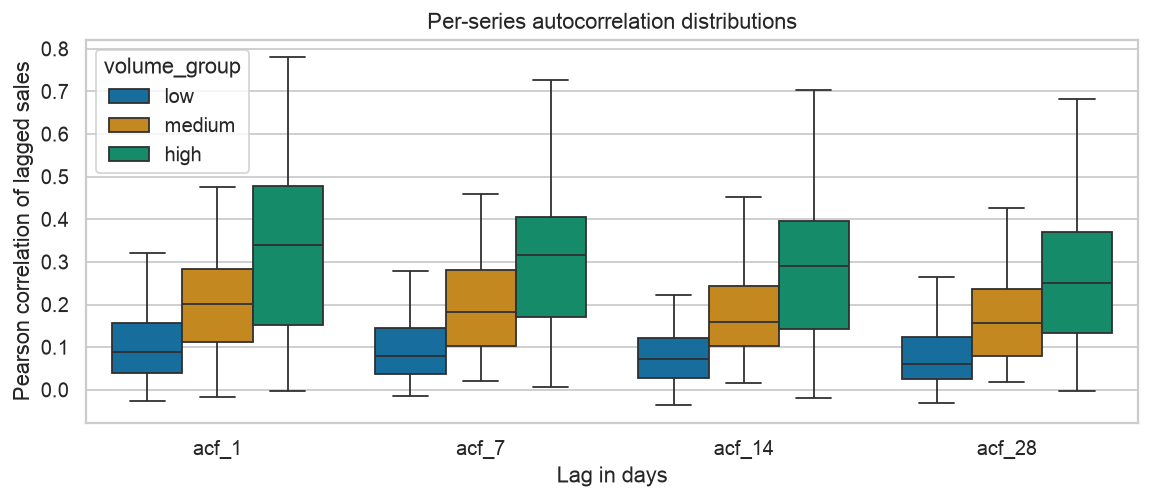

In [5]:
print("Median autocorrelations:", facts["acf_medians"])
for name in ["04_seasonality.png", "05_autocorrelation.png"]:
    display(Image(filename=str(data_path(cfg, "reports") / "figures" / name)))

## Zero-sales runs, sparsity and intermittency

ADI = observed days / positive-sale days; positive CV² uses only positive-sale sizes. Configurable descriptive ADI/CV² thresholds are 1.32/0.49. Missing targets break zero runs. Long zero stretches can reflect launch timing or other availability uncertainty and are retained.

,series_id,volume_group,zero_fraction,max_zero_run,adi,positive_cv2,pattern
0,FOODS_1_004__TX_2,high,0.3354,404,1.5046,0.5500,lumpy
1,FOODS_1_019__WI_1,high,0.2760,190,1.3811,0.4267,intermittent
2,FOODS_1_026__CA_2,medium,0.5730,105,2.3420,0.4821,intermittent
3,FOODS_1_038__WI_2,low,0.7340,85,3.7599,0.5056,lumpy
4,FOODS_1_056__WI_2,low,0.8984,1007,9.8415,0.2651,intermittent


Pattern counts: {'intermittent': 175, 'lumpy': 54, 'smooth': 8, 'erratic': 3}
Pooled zero-sales fraction: 0.6933


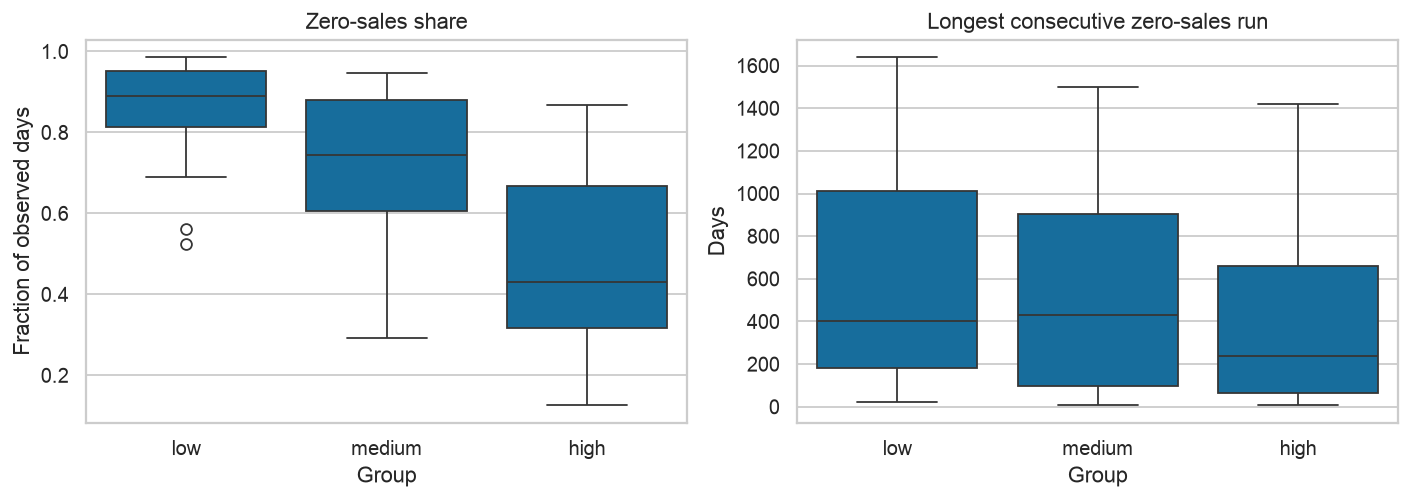

In [6]:
display(stats[["series_id", "volume_group", "zero_fraction", "max_zero_run", "adi", "positive_cv2", "pattern"]].head(5).round(4))
print("Pattern counts:", facts["patterns"])
print("Pooled zero-sales fraction:", round(facts["zero_fraction_pooled"], 4))
display(Image(filename=str(data_path(cfg, "reports") / "figures/06_sparsity.png")))

## Events, holidays and state SNAP flags

Compare normalized sales on listed event days vs other days and on the series state's SNAP-flagged days. Named events include exposure counts. Weekday, price, season and trend confounding remain; no causal effect or significance is claimed. Future SNAP is conservatively excluded from model inputs.

SNAP-flag / other-day ratios: {'CA': 1.048, 'TX': 1.06, 'WI': 1.08}


,event_name_1,mean_relative_sales,series_days,distinct_dates
0,Chanukah End,1.046,1200,5
14,MemorialDay,0.854,1200,5
28,ValentinesDay,0.909,1200,5
27,Thanksgiving,0.553,1200,5
26,SuperBowl,1.016,1200,5
25,StPatricksDay,0.947,1200,5
24,Ramadan starts,1.010,1200,5
23,Purim End,1.171,1200,5


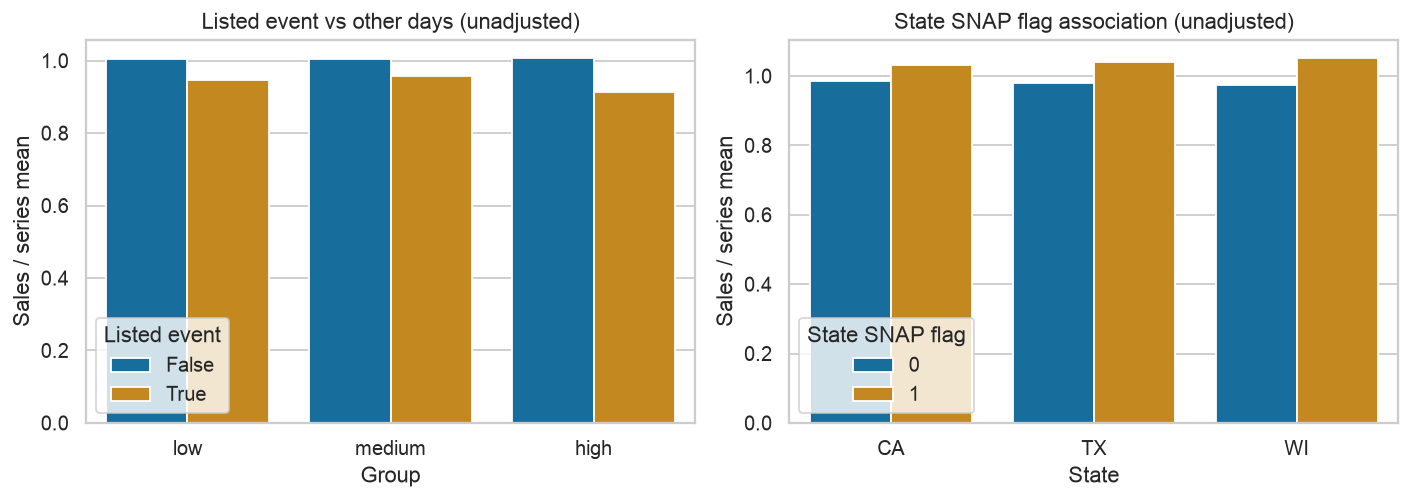

In [7]:
print("SNAP-flag / other-day ratios:", facts["snap_day_ratio_by_state"])
display(summaries["named_events"].sort_values("distinct_dates", ascending=False).head(8).round(3))
display(Image(filename=str(data_path(cfg, "reports") / "figures/07_events_snap.png")))

## Historical prices and sales associations

Plot representative listed prices relative to each series' median. Correlations use paired observed days within each series, at least 30 pairs, and nonconstant prices and sales; undefined correlations are omitted, not set to zero. Weekly prices repeat across daily rows. Future actual prices are prohibited in backtests.

Missing price share: 0.2444
Usable within-series price correlations: 159
Median price/sales correlation: -0.0471


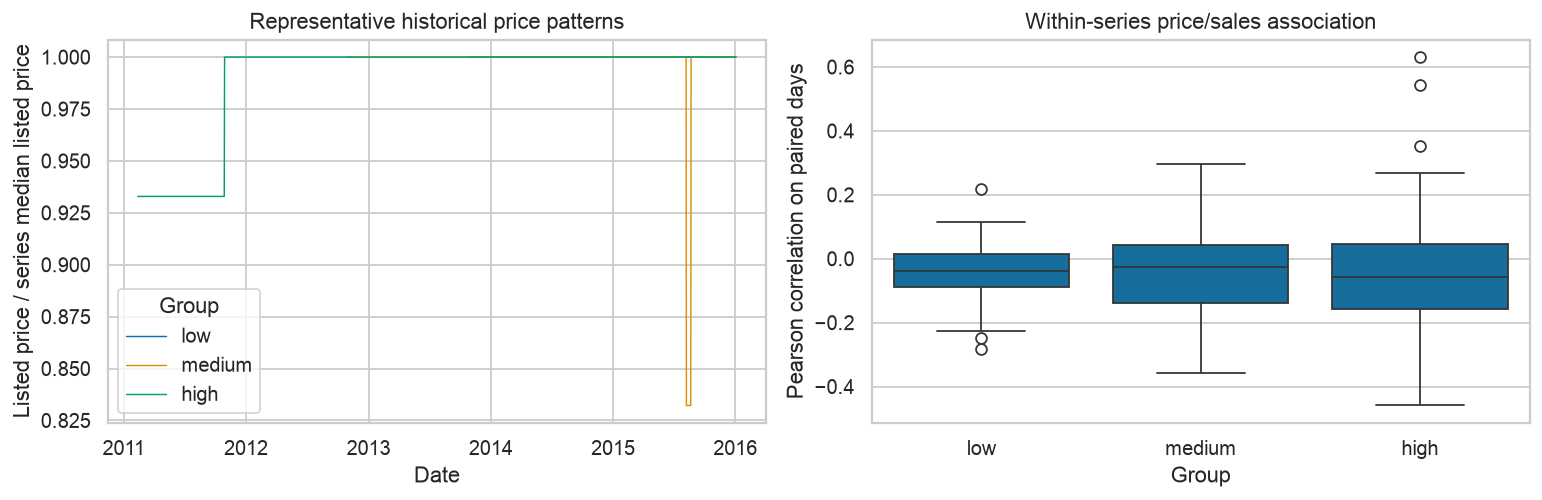

In [8]:
print("Missing price share:", round(facts["price_missing_fraction"], 4))
print("Usable within-series price correlations:", facts["valid_price_correlations"])
print("Median price/sales correlation:", round(facts["median_price_correlation"], 4))
display(Image(filename=str(data_path(cfg, "reports") / "figures/08_prices.png")))

## Findings and limits

The complete five findings, supporting evidence, forecasting implications and limits are in `reports/eda_findings.md`. Statistics are in `reports/eda_series_statistics.csv` and the seasonal/event/SNAP tables. No inference about latent demand, stockouts or price elasticity follows from these descriptions. No forecasting models or fitted preprocessing were added.